# 03 - Model Training Pipeline (Classification)

Author: Ahmed Shahzad

**Goal:** train one classifier for each dataset using a complete, repeatable scikit-learn workflow, compare several candidate models fairly, measure the final model on data it never saw, and save everything the web apps need.

| | Maternal Health Risk | HTRU2 Pulsar |
|---|---|---|
| Target | `RiskLevel` (low / mid / high) | `is_pulsar` (0 / 1) |
| Candidates | Logistic Regression, Random Forest, Gradient Boosting | Logistic Regression, Random Forest, Hist. Gradient Boosting |
| Chosen by | cross-validated macro F1 (training data only) | cross-validated PR-AUC (training data only) |
| Final check | accuracy, macro F1, high-risk recall, confusion matrix | precision, recall, F1, ROC-AUC, PR-AUC, confusion matrix |

The test set is touched **once**, at the very end of each part.

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_recall_fscore_support, precision_score, recall_score,
    roc_auc_score, precision_recall_curve, roc_curve,
)
from sklearn.model_selection import (
    RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 90

RANDOM_STATE = 42
TEST_SIZE = 0.2
MODEL_DIR = Path("models")
FIG = Path("reports/figures")
MODEL_DIR.mkdir(exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

RISK_ORDER = ["low risk", "mid risk", "high risk"]
MAT_FEATURES = ["Age", "SystolicBP", "DiastolicBP", "BS", "BodyTemp", "HeartRate"]
PUL_FEATURES = ["IP_Mean", "IP_SD", "IP_Kurtosis", "IP_Skewness", "DM_Mean", "DM_SD", "DM_Kurtosis", "DM_Skewness"]

mat = pd.read_csv("data/processed/maternal_clean.csv")
pul = pd.read_csv("data/processed/pulsar_clean.csv")
print("Maternal:", mat.shape, "| Pulsar:", pul.shape)

Maternal: (451, 7) | Pulsar: (17898, 9)


## Helper functions

Two small helpers are shared by both parts: one builds the "feature description" the web apps read (range, typical value and a 101-point distribution grid), the other builds the representative examples shown as presets in the UI.

In [2]:
def to_py(x):
    """Make numpy values JSON-friendly."""
    if isinstance(x, (np.floating, float)):
        return float(x)
    if isinstance(x, (np.integer, int)):
        return int(x)
    if isinstance(x, np.ndarray):
        return [to_py(v) for v in x.tolist()]
    if isinstance(x, dict):
        return {k: to_py(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [to_py(v) for v in x]
    return x


def describe_features(frame, decimals):
    """Per-feature info for the apps: training range, median default and a quantile grid."""
    out = []
    for col in frame.columns:
        s = frame[col]
        grid = np.quantile(s, np.linspace(0, 1, 101))
        out.append({
            "name": col,
            "kind": "number",
            "min": round(float(s.min()), 4),
            "max": round(float(s.max()), 4),
            "p05": round(float(s.quantile(.05)), 4),
            "p50": round(float(s.median()), 4),
            "p95": round(float(s.quantile(.95)), 4),
            "default": round(float(s.median()), decimals),
            "grid": [round(float(v), 4) for v in grid],
        })
    return out


def percentile_of(sample, value):
    """Percentile rank (0-100) of one value within a sample; ties count half."""
    sample = np.asarray(sample)
    return float(100 * ((sample < value).sum() + 0.5 * (sample == value).sum()) / len(sample))


def class_profile(frame, y, class_values, class_names):
    """For each class: the percentile of that class's median value for every feature."""
    prof = {}
    for val, name in zip(class_values, class_names):
        med = frame[y == val].median()
        prof[name] = [round(percentile_of(frame[c], med[c]), 1) for c in frame.columns]
    return prof


def pick_examples(model, X_test, y_test, class_values, class_names, decimals, predict_fn):
    """One real, correctly classified test row per class: the one closest to that class's median."""
    pred = predict_fn(X_test)
    scale = X_test.std().replace(0, 1)
    examples = []
    for val, name in zip(class_values, class_names):
        ok = X_test[(y_test.values == val) & (pred == val)]
        med = ok.median()
        row = ok.iloc[int(((ok - med).abs() / scale).sum(axis=1).values.argmin())]
        examples.append({
            "name": name,
            "values": {c: round(float(row[c]), decimals) for c in X_test.columns},
            "actual": name,
        })
    return examples

# Part A - Maternal Health Risk: predict `RiskLevel`

In [3]:
y_mat = mat["RiskLevel"].map({r: i for i, r in enumerate(RISK_ORDER)})   # low=0, mid=1, high=2
X_mat = mat[MAT_FEATURES]

Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X_mat, y_mat, test_size=TEST_SIZE, stratify=y_mat, random_state=RANDOM_STATE
)
print(f"Train: {len(Xm_train)} | Test: {len(Xm_test)}")
print("Train class share:", ym_train.value_counts(normalize=True).sort_index().round(3).to_dict())
print("Test  class share:", ym_test.value_counts(normalize=True).sort_index().round(3).to_dict())

Train: 360 | Test: 91
Train class share: {0: 0.517, 1: 0.236, 2: 0.247}
Test  class share: {0: 0.516, 1: 0.231, 2: 0.253}


The duplicates were removed in notebook 01, so no row appears on both sides of the split. The class shares are almost identical in train and test because we used `stratify`.

### Cross-validation of the candidate models (training data only)

Every candidate is scored with 5-fold cross-validation repeated 3 times, so one lucky split cannot decide the winner. We use **macro F1** (the average of the per-class F1 scores) because it treats low, mid and high risk equally.

In [4]:
mat_candidates = {
    "Logistic Regression": Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=3000, class_weight="balanced")),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
rows = []
for name, model in mat_candidates.items():
    res = cross_validate(model, Xm_train, ym_train, cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=-1)
    rows.append({
        "model": name,
        "cv accuracy": res["test_accuracy"].mean(),
        "cv macro F1": res["test_f1_macro"].mean(),
        "macro F1 std": res["test_f1_macro"].std(),
    })
mat_cv = pd.DataFrame(rows).set_index("model").round(3)
display(mat_cv)

mat_best_name = mat_cv["cv macro F1"].idxmax()
print("Selected:", mat_best_name)

,cv accuracy,cv macro F1,macro F1 std
model,,,
Logistic Regression,0.593,0.549,0.043
Random Forest,0.669,0.616,0.042
Gradient Boosting,0.676,0.615,0.052


Selected: Random Forest


### Fit the selected model and evaluate on the untouched test set

In [5]:
mat_model = mat_candidates[mat_best_name]
mat_model.fit(Xm_train, ym_train)

ym_pred = mat_model.predict(Xm_test)
mat_cm = confusion_matrix(ym_test, ym_pred, labels=[0, 1, 2])
prec, rec, f1, sup = precision_recall_fscore_support(ym_test, ym_pred, labels=[0, 1, 2], zero_division=0)

mat_metrics = {
    "model_name": mat_best_name,
    "accuracy": round(accuracy_score(ym_test, ym_pred), 4),
    "macro_f1": round(f1_score(ym_test, ym_pred, average="macro"), 4),
    "high_risk_recall": round(float(rec[2]), 4),
    "cv_macro_f1": round(float(mat_cv.loc[mat_best_name, "cv macro F1"]), 4),
    "n_train": int(len(Xm_train)),
    "n_test": int(len(Xm_test)),
    "per_class": {
        name: {"precision": round(float(prec[i]), 3), "recall": round(float(rec[i]), 3),
               "f1": round(float(f1[i]), 3), "support": int(sup[i])}
        for i, name in enumerate(RISK_ORDER)
    },
}
display(pd.DataFrame(mat_metrics["per_class"]).T)
print({k: v for k, v in mat_metrics.items() if k != "per_class"})

,precision,recall,f1,support
low risk,0.774,0.872,0.820,47.0
mid risk,0.308,0.190,0.235,21.0
high risk,0.720,0.783,0.750,23.0


{'model_name': 'Random Forest', 'accuracy': 0.6923, 'macro_f1': 0.6018, 'high_risk_recall': 0.7826, 'cv_macro_f1': 0.616, 'n_train': 360, 'n_test': 91}


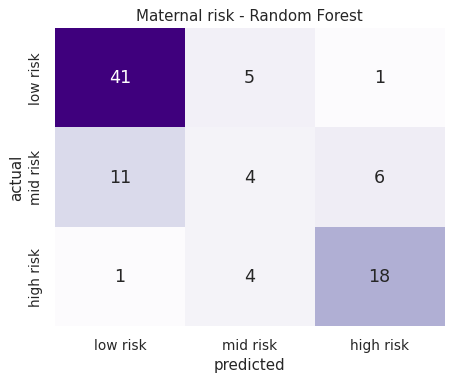

In [6]:
fig, ax = plt.subplots(figsize=(5.2, 4.4))
sns.heatmap(mat_cm, annot=True, fmt="d", cmap="Purples", cbar=False, ax=ax,
            xticklabels=RISK_ORDER, yticklabels=RISK_ORDER, annot_kws={"size": 14})
ax.set_xlabel("predicted")
ax.set_ylabel("actual")
ax.set_title(f"Maternal risk - {mat_best_name}")
fig.tight_layout()
fig.savefig(FIG / "maternal_confusion_matrix.png", dpi=150)
plt.show()

### Which vitals does the model rely on?

**Permutation importance** shuffles one feature at a time on the test set and measures how much the macro F1 drops. A big drop means the model leans on that feature.

,macro F1 drop
BS,0.1439
SystolicBP,0.1186
BodyTemp,0.0249
Age,0.0000
DiastolicBP,0.0000
HeartRate,0.0000


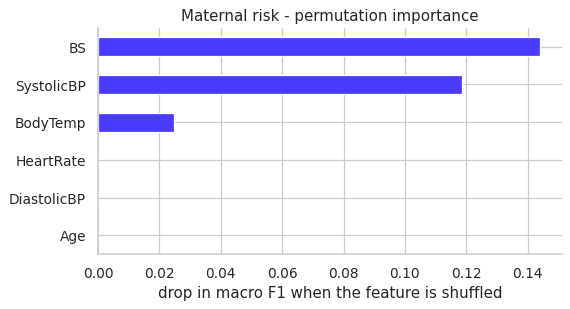

In [7]:
imp = permutation_importance(
    mat_model, Xm_test, ym_test, scoring="f1_macro", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1
)
mat_imp = (pd.Series(imp.importances_mean, index=MAT_FEATURES).clip(lower=0)
           .sort_values(ascending=False))
display(mat_imp.round(4).to_frame("macro F1 drop"))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
mat_imp.sort_values().plot.barh(ax=ax, color="#4B3BFF")
ax.set_xlabel("drop in macro F1 when the feature is shuffled")
ax.set_title("Maternal risk - permutation importance")
sns.despine()
fig.tight_layout()
fig.savefig(FIG / "maternal_importance.png", dpi=150)
plt.show()

### How to read the Maternal results

- **Accuracy and macro F1** are modest. That is the honest level for this data: after removing the duplicated rows, the model can no longer "remember" test rows, and notebook 01 showed that identical vitals sometimes carry different labels. Scores quoted online that are much higher usually come from a split that leaks duplicates into the test set.
- **High-risk recall** is the number that matters most in practice: out of all women who truly are high risk, how many does the model flag? A missed high-risk case is worse than a false alarm.
- **Mid risk is the weak spot.** The model catches only a small share of true mid-risk women (see the per-class recall table and the confusion matrix); most of them are labelled low or high. Mistakes between low and high are rare, so when the model says *high risk* it is usually right. The middle class has no sharp boundary in this data, which matches what the EDA showed.
- Only `BS`, `SystolicBP` and `BodyTemp` have a visible importance; the other vitals add little once those are known.
- This is an educational model trained on a small dataset. It is **not** a medical device.

In [8]:
mat_info = {
    "model_file": "maternal_model.joblib",
    "target": "RiskLevel",
    "task": "multiclass",
    "classes": RISK_ORDER,
    "features": describe_features(X_mat, 1),
    "metrics": mat_metrics,
    "confusion_matrix": mat_cm.tolist(),
    "importance": [{"name": k, "value": round(float(v), 4)} for k, v in mat_imp.items()],
    "class_profile": class_profile(X_mat, y_mat, [0, 1, 2], RISK_ORDER),
    "examples": pick_examples(mat_model, Xm_test, ym_test, [0, 1, 2], RISK_ORDER, 1, mat_model.predict),
}
for f in mat_info["features"]:
    if f["name"] in ("Age", "SystolicBP", "DiastolicBP", "HeartRate"):
        f["default"] = int(round(f["default"]))
print([e["name"] for e in mat_info["examples"]])

['low risk', 'mid risk', 'high risk']


# Part B - HTRU2 Pulsar Candidates: predict `is_pulsar`

In [9]:
y_pul = pul["is_pulsar"]
X_pul = pul[PUL_FEATURES]

Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X_pul, y_pul, test_size=TEST_SIZE, stratify=y_pul, random_state=RANDOM_STATE
)
print(f"Train: {len(Xp_train):,} | Test: {len(Xp_test):,}")
print(f"Pulsar share - train: {yp_train.mean():.2%} | test: {yp_test.mean():.2%}")

Train: 14,318 | Test: 3,580
Pulsar share - train: 9.16% | test: 9.16%


### Cross-validation of the candidate models (training data only)

With only about 9% positives, **PR-AUC** (average precision) is a much more honest score than accuracy or even ROC-AUC. We also report F1 at the default 0.5 threshold.

In [10]:
pul_candidates = {
    "Logistic Regression": Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=5000, class_weight="balanced")),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Hist. Gradient Boosting": HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300, class_weight="balanced", random_state=RANDOM_STATE
    ),
}

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in pul_candidates.items():
    res = cross_validate(model, Xp_train, yp_train, cv=cv5,
                         scoring=["average_precision", "roc_auc", "f1"], n_jobs=-1)
    rows.append({
        "model": name,
        "cv PR-AUC": res["test_average_precision"].mean(),
        "cv ROC-AUC": res["test_roc_auc"].mean(),
        "cv F1 @0.5": res["test_f1"].mean(),
    })
pul_cv = pd.DataFrame(rows).set_index("model").round(3)
display(pul_cv)

pul_best_name = pul_cv["cv PR-AUC"].idxmax()
print("Selected:", pul_best_name)

,cv PR-AUC,cv ROC-AUC,cv F1 @0.5
model,,,
Logistic Regression,0.923,0.977,0.842
Random Forest,0.927,0.973,0.887
Hist. Gradient Boosting,0.925,0.977,0.860


Selected: Random Forest


### Tune the decision threshold (still on training data only)

A classifier outputs a probability. The default rule "pulsar if probability >= 0.5" is rarely the best one when classes are imbalanced. We get an honest probability for every training row from **out-of-fold** predictions (each row is predicted by a model that never saw it) and pick the threshold that maximises F1.

Best threshold (out-of-fold F1): 0.54  ->  F1 = 0.889


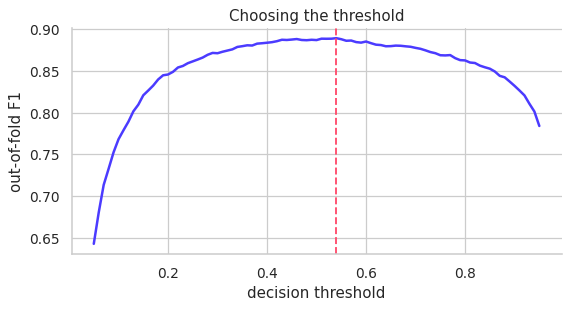

In [11]:
pul_model = pul_candidates[pul_best_name]

oof = cross_val_predict(pul_model, Xp_train, yp_train, cv=cv5, method="predict_proba", n_jobs=-1)[:, 1]
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
oof_f1 = np.array([f1_score(yp_train, oof >= t) for t in grid])
THRESHOLD = float(grid[int(oof_f1.argmax())])
print(f"Best threshold (out-of-fold F1): {THRESHOLD:.2f}  ->  F1 = {oof_f1.max():.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(grid, oof_f1, color="#4B3BFF", lw=2)
ax.axvline(THRESHOLD, color="#FF4D6D", ls="--")
ax.set_xlabel("decision threshold")
ax.set_ylabel("out-of-fold F1")
ax.set_title("Choosing the threshold")
sns.despine()
fig.tight_layout()
plt.show()

### Fit on the full training set and evaluate on the untouched test set

In [12]:
pul_model.fit(Xp_train, yp_train)
p_test = pul_model.predict_proba(Xp_test)[:, 1]
yp_pred = (p_test >= THRESHOLD).astype(int)

pul_cm = confusion_matrix(yp_test, yp_pred, labels=[0, 1])
pul_metrics = {
    "model_name": pul_best_name,
    "threshold": THRESHOLD,
    "precision": round(precision_score(yp_test, yp_pred), 4),
    "recall": round(recall_score(yp_test, yp_pred), 4),
    "f1": round(f1_score(yp_test, yp_pred), 4),
    "roc_auc": round(roc_auc_score(yp_test, p_test), 4),
    "pr_auc": round(average_precision_score(yp_test, p_test), 4),
    "f1_at_0_5": round(f1_score(yp_test, (p_test >= 0.5).astype(int)), 4),
    "cv_pr_auc": round(float(pul_cv.loc[pul_best_name, "cv PR-AUC"]), 4),
    "n_train": int(len(Xp_train)),
    "n_test": int(len(Xp_test)),
    "n_test_pulsars": int(yp_test.sum()),
}
print(json.dumps(pul_metrics, indent=2))

{
  "model_name": "Random Forest",
  "threshold": 0.54,
  "precision": 0.9057,
  "recall": 0.878,
  "f1": 0.8916,
  "roc_auc": 0.972,
  "pr_auc": 0.9304,
  "f1_at_0_5": 0.8892,
  "cv_pr_auc": 0.927,
  "n_train": 14318,
  "n_test": 3580,
  "n_test_pulsars": 328
}


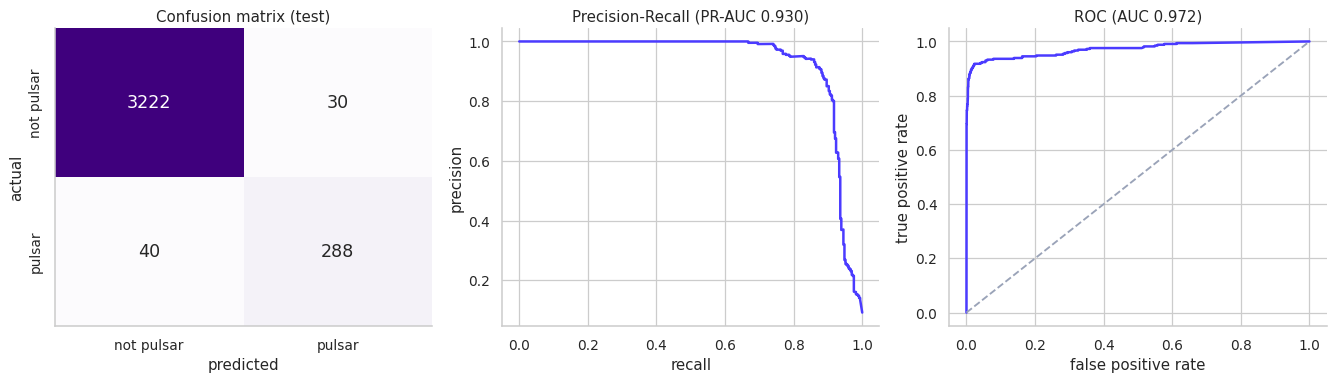

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

sns.heatmap(pul_cm, annot=True, fmt="d", cmap="Purples", cbar=False, ax=axes[0],
            xticklabels=["not pulsar", "pulsar"], yticklabels=["not pulsar", "pulsar"], annot_kws={"size": 14})
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("actual"); axes[0].set_title("Confusion matrix (test)")

pr, rc, _ = precision_recall_curve(yp_test, p_test)
axes[1].plot(rc, pr, color="#4B3BFF", lw=2)
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title(f"Precision-Recall (PR-AUC {pul_metrics['pr_auc']:.3f})")

fpr, tpr, _ = roc_curve(yp_test, p_test)
axes[2].plot(fpr, tpr, color="#4B3BFF", lw=2)
axes[2].plot([0, 1], [0, 1], color="#9AA3B8", ls="--")
axes[2].set_xlabel("false positive rate"); axes[2].set_ylabel("true positive rate")
axes[2].set_title(f"ROC (AUC {pul_metrics['roc_auc']:.3f})")

sns.despine()
fig.tight_layout()
fig.savefig(FIG / "pulsar_evaluation.png", dpi=150)
plt.show()

,PR-AUC drop
IP_Kurtosis,0.6124
IP_Skewness,0.0958
DM_SD,0.0232
IP_Mean,0.0228
DM_Mean,0.0109
DM_Skewness,0.0038
DM_Kurtosis,0.0017
IP_SD,0.0009


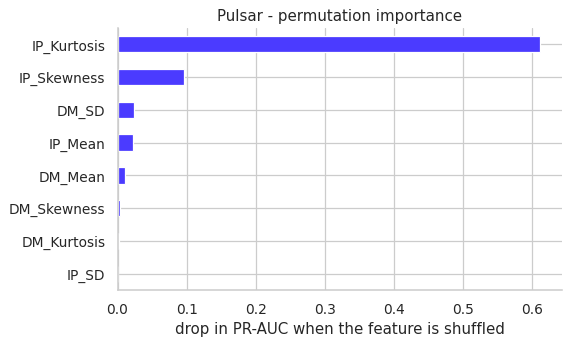

In [14]:
imp = permutation_importance(
    pul_model, Xp_test, yp_test, scoring="average_precision", n_repeats=20,
    random_state=RANDOM_STATE, n_jobs=-1
)
pul_imp = pd.Series(imp.importances_mean, index=PUL_FEATURES).clip(lower=0).sort_values(ascending=False)
display(pul_imp.round(4).to_frame("PR-AUC drop"))

fig, ax = plt.subplots(figsize=(6.5, 4))
pul_imp.sort_values().plot.barh(ax=ax, color="#4B3BFF")
ax.set_xlabel("drop in PR-AUC when the feature is shuffled")
ax.set_title("Pulsar - permutation importance")
sns.despine()
fig.tight_layout()
fig.savefig(FIG / "pulsar_importance.png", dpi=150)
plt.show()

### How to read the Pulsar results

- **Precision** answers: of the candidates the model calls pulsars, how many really are? **Recall** answers: of all real pulsars, how many does the model find? Both are high. Tuning the threshold improved F1 only marginally over the default 0.5 (compare `f1` with `f1_at_0_5`), because the Random Forest was already well balanced; we still store the tuned value so the apps match this notebook exactly.
- `IP_Kurtosis` dominates the importance ranking by a wide margin, matching the EDA, where it was the strongest single feature.
- ROC-AUC looks excellent partly because there are so many easy negatives; PR-AUC is the stricter number.
- In a real survey the cost is asymmetric: a missed pulsar is a lost discovery, while a false alarm only costs an astronomer a quick look. If recall mattered more, we would lower the threshold; `model_info.json` stores the threshold so the apps stay in sync with this notebook.

In [15]:
pul_info = {
    "model_file": "pulsar_model.joblib",
    "target": "is_pulsar",
    "task": "binary",
    "classes": ["not pulsar", "pulsar"],
    "positive_class": "pulsar",
    "threshold": THRESHOLD,
    "features": describe_features(X_pul, 2),
    "metrics": pul_metrics,
    "confusion_matrix": pul_cm.tolist(),
    "importance": [{"name": k, "value": round(float(v), 4)} for k, v in pul_imp.items()],
    "class_profile": class_profile(X_pul, y_pul, [0, 1], ["not pulsar", "pulsar"]),
    "examples": pick_examples(
        pul_model, Xp_test, yp_test, [0, 1], ["not pulsar", "pulsar"], 3,
        lambda X: (pul_model.predict_proba(X)[:, 1] >= THRESHOLD).astype(int),
    ),
}
print([e["name"] for e in pul_info["examples"]])

['not pulsar', 'pulsar']


# Part C - Save and verify

In [16]:
joblib.dump(mat_model, MODEL_DIR / "maternal_model.joblib", compress=3)
joblib.dump(pul_model, MODEL_DIR / "pulsar_model.joblib", compress=3)

info = {"maternal": mat_info, "pulsar": pul_info}
(MODEL_DIR / "model_info.json").write_text(json.dumps(to_py(info), indent=1))

for p in sorted(MODEL_DIR.iterdir()):
    print(f"{p.name:24s} {p.stat().st_size / 1024:8.1f} KB")

maternal_model.joblib      1047.4 KB
model_info.json              23.8 KB
pulsar_model.joblib        4352.6 KB


### Check: reload the saved models and predict one real example each

In [17]:
m2 = joblib.load(MODEL_DIR / "maternal_model.joblib")
p2 = joblib.load(MODEL_DIR / "pulsar_model.joblib")

for ex in mat_info["examples"]:
    row = pd.DataFrame([ex["values"]], columns=MAT_FEATURES)
    probs = m2.predict_proba(row)[0]
    print(f"maternal example '{ex['name']}': predicted {RISK_ORDER[int(probs.argmax())]} ({probs.max():.0%})")

for ex in pul_info["examples"]:
    row = pd.DataFrame([ex["values"]], columns=PUL_FEATURES)
    p = p2.predict_proba(row)[0, 1]
    print(f"pulsar example '{ex['name']}': P(pulsar) = {p:.1%} -> {'pulsar' if p >= THRESHOLD else 'not pulsar'}")

maternal example 'low risk': predicted low risk (55%)
maternal example 'mid risk': predicted mid risk (83%)


maternal example 'high risk': predicted high risk (97%)
pulsar example 'not pulsar': P(pulsar) = 0.6% -> not pulsar
pulsar example 'pulsar': P(pulsar) = 99.7% -> pulsar


## Summary

- Both models are full scikit-learn objects saved with `joblib`, chosen by cross-validation on training data only and evaluated once on a held-out test set.
- `models/model_info.json` stores each model's input fields, training ranges, metrics, confusion matrix, feature importance, the pulsar decision threshold, and real example rows. `common.py` and both web apps read it, so the apps always match the trained models.
- Maternal accuracy is modest because the data was cleaned honestly (duplicates removed) and mid risk is hard to separate; the pulsar model is strong, and its threshold was tuned for F1, not for maximum recall.
- Run the apps: `python flask_app.py` or `python gradio_app.py`.